In [2]:
from rdkit import Chem

import numpy as np
import pandas as pd
import torch
from torch_geometric.data import Data
from torch_geometric.data import InMemoryDataset
from torch_geometric.loader import DataLoader

import torch.nn as nn
import torch.nn.functional as F
import torch_geometric.nn as pyg_nn
from tqdm.auto import tqdm

from rdkit.Chem import rdMolDescriptors
from rdkit.Chem import Descriptors
from rdkit.Chem.rdMolDescriptors import CalcNumHBA
from rdkit.Chem.rdMolDescriptors import CalcNumHBD
import os
import matplotlib.pyplot as plt
#os.chdir('/home/ufslab223/Shared/KSW/torch_geometric/TLC_RF')  # 실제 파일이 있는 상위 폴더로 변경 (vs code의 remote SSH 사용시 위치 잘 못잡아서..)

In [2]:
# gpu 메모리 비우기
torch.cuda.empty_cache()

In [3]:
# 여기선 평균, 표준편차만 저장하고 표준화는 graph만들면서 진행

def standardization(DB_df, columns_list, backup=False):
    # columns_list : list of prop

    mean = DB_df[columns_list].mean(axis=0)
    std = DB_df[columns_list].std(axis=0)
    if backup==True:
        np.save('standardization/backup/mean_backup.npy', np.array(mean, dtype = np.float32))
        np.save('standardization/backup/std_backup.npy', np.array(std, dtype = np.float32))
    else:
        np.save('standardization/mean.npy', np.array(mean, dtype = np.float32))
        np.save('standardization/std.npy', np.array(std, dtype = np.float32))
        
    return None


def inverse_standardization(pred_nd_array, mean, std):
    return pred_nd_array * std + mean

## Cheon lab's Data

In [12]:
import sys
sys.path.append('../')
from functions import delete_weird_mol_and_None_except_Nan, delete_metal_mol_except_Nan


Cheon_lab_data = pd.read_csv('/home/ufslab223/Shared/KSW/torch_geometric/TLC_RF/cheon_lab_ALL.csv')
# canonical smiles 혹시 몰라 한번 더
Cheon_lab_data['Smiles'] = [Chem.MolToSmiles(Chem.MolFromSmiles(smiles)) if pd.notna(smiles) else None for smiles in Cheon_lab_data['Smiles']]

Cheon_lab_data = Cheon_lab_data[pd.notna(Cheon_lab_data['Smiles'])]
Cheon_lab_data = Cheon_lab_data[Cheon_lab_data['Smiles'].str.find('.')==-1]

Cheon_lab_data = delete_weird_mol_and_None_except_Nan(Cheon_lab_data, 'Smiles')
Cheon_lab_data = delete_metal_mol_except_Nan(Cheon_lab_data, 'Smiles')
# 원소 하나짜리 제거
Cheon_lab_data= Cheon_lab_data[[Chem.MolFromSmiles(smiles).GetNumBonds()!=0 for smiles in Cheon_lab_data['Smiles']]]

# 기존 DB에 없는 것만 남김김
Cheon_lab_data = Cheon_lab_data[~Cheon_lab_data['Smiles'].isin(united_['Smiles'])]
Cheon_lab_data['org_idx'] = Cheon_lab_data.index
Cheon_lab_data.reset_index(drop=True, inplace=True)
Cheon_lab_data

55번째 분자 금속원소 포함됨
191번째 분자 금속원소 포함됨
563번째 분자 금속원소 포함됨
564번째 분자 금속원소 포함됨
567번째 분자 금속원소 포함됨
568번째 분자 금속원소 포함됨
793번째 분자 금속원소 포함됨
797번째 분자 금속원소 포함됨
798번째 분자 금속원소 포함됨


,카테고리 분류,카테고리 이름,관리번호,사내관리번호,물품명,서브네임,위치 경로,보관함 경로,브랜드,등록자,...,사용횟수,USP/Phase,내경(ID),Particle size,길이,Pore size,Carbon load(%),Endcapped,Smiles,org_idx
0,화학물질,시약,D-1-1751,-,"2,5-dimethyl-1-phenyl-1h-pyrrole-3-carboxylic",-,D-1,D-1,Enamine,박상준,...,-,-,-,-,-,-,-,-,Cc1cc(C(=O)O)c(C)n1-c1ccccc1,0
1,화학물질,시약,S-10-1740,-,"1,2-Bis(diphenylphosphino)benzene",97%,S-10,S-10,Sigma-Aldrich,박상준,...,-,-,-,-,-,-,-,-,c1ccc(P(c2ccccc2)c2ccccc2P(c2ccccc2)c2ccccc2)cc1,2
2,화학물질,시약,D-5-1739,-,Triisopropyl phosphite,95%,D-1,D-1,Sigma-Aldrich,박상준,...,-,-,-,-,-,-,-,-,CC(C)OP(OC(C)C)OC(C)C,3
3,화학물질,시약,S-6s-1738,-,2-Fluorobenzonitrile,98%,S-6,S-6,Sigma-Aldrich,박상준,...,-,-,-,-,-,-,-,-,N#Cc1ccccc1F,4
4,화학물질,시약,S-3L-1737,-,Morpholino(phenyl)methanone,-,"화학과 유기합성연구실의 물품 저장소,S-3L",S-3L,BLDpharm,박상준,...,-,-,-,-,-,-,-,-,O=C(c1ccccc1)N1CCOCC1,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
739,화학물질,시약,R-B-1,-,Phosphorus oxychloride,-,R-B,R-B,DAEJUNG (대정),박진재,...,-,-,-,-,-,-,-,-,O=P(Cl)(Cl)Cl,785
740,화학물질,시약,I-N-2,-,Thiophosphoryl chloride,-,I-N,I-N,TCI(Tokyo Chemical Industry),박진재,...,-,-,-,-,-,-,-,-,S=P(Cl)(Cl)Cl,786
741,화학물질,시약,R-1-3,-,Phosphorus pentasulfide,-,R-1,R-1,Sigma-Aldrich,박진재,...,-,-,-,-,-,-,-,-,S=P12SP3(=S)SP(=S)(S1)SP(=S)(S2)S3,787
742,화학물질,시약,I-2-3,-,Boron-tribromide,-,I-2,I-2,Sigma-Aldrich,박진재,...,-,-,-,-,-,-,-,-,BrB(Br)Br,788


In [ ]:
import sys
sys.path.append('../')

from functions import delete_weird_mol_and_None_except_Nan, delete_metal_mol_except_Nan

df = pd.DataFrame({'Smiles': Smiles_list, 'org_idx': Smiles_list.index})

df_1 = delete_weird_mol_and_None_except_Nan(df, 'Smiles')
df_2 = delete_metal_mol_except_Nan(df_1, 'Smiles')
# 원소 하나짜리 제거
df_3= df_2[[Chem.MolFromSmiles(smiles).GetNumBonds()!=0 for smiles in df_2['Smiles']]]

# 기존 DB에 없는 것만 남김김
df_4 = df_3[~df_3['Smiles'].isin(united_['Smiles'])]
df_4['org_idx'] = df_4.index
df_4.reset_index(drop=True, inplace=True)
df_4

55번째 분자 금속원소 포함됨
191번째 분자 금속원소 포함됨
563번째 분자 금속원소 포함됨
564번째 분자 금속원소 포함됨
567번째 분자 금속원소 포함됨
568번째 분자 금속원소 포함됨
793번째 분자 금속원소 포함됨
797번째 분자 금속원소 포함됨
798번째 분자 금속원소 포함됨


/tmp/ipykernel_3365202/558163861.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_4['org_idx'] = df_4.index


,Smiles,org_idx
0,Cc1cc(C(=O)O)c(C)n1-c1ccccc1,0
1,c1ccc(P(c2ccccc2)c2ccccc2P(c2ccccc2)c2ccccc2)cc1,2
2,CC(C)OP(OC(C)C)OC(C)C,3
3,N#Cc1ccccc1F,4
4,O=C(c1ccccc1)N1CCOCC1,5
...,...,...
739,O=P(Cl)(Cl)Cl,791
740,S=P(Cl)(Cl)Cl,792
741,S=P12SP3(=S)SP(=S)(S1)SP(=S)(S2)S3,794
742,BrB(Br)Br,795


## 용매 비율 생성

In [6]:
def reaction_trend_set(reaction_mol_list):
    reaction_smiles = [smiles for smiles in reaction_mol_list for i in range(11)]
    exp_elu1_smiles = ['CCOC(C)=O' for i in range(len(reaction_smiles))]
    exp_elu2_smiles = ['CCCCCC' for i in range(len(reaction_smiles))]
    exp_ratio1 = [round(i,1) for ii in range(len(reaction_mol_list)) for i in np.arange(0,1.05,0.1)]
    exp_ratio2 = np.round(1- np.array(exp_ratio1), 1)

    trend_set = pd.DataFrame({
        'Smiles': reaction_smiles,
        'elu1_smiles':exp_elu1_smiles,
        'elu2_smiles':exp_elu2_smiles,
        'ratio1':exp_ratio1,
        'ratio2':exp_ratio2,
        'Rf':[np.nan for i in range(len(reaction_smiles))]
    })

    trend_set['sample_id'] = trend_set.index

    return trend_set

In [ ]:
Cheon_lab_set = reaction_trend_set(Cheon_lab_data["Smiles"])

In [13]:
Cheon_lab_set

,Smiles,elu1_smiles,elu2_smiles,ratio1,ratio2,Rf,sample_id
0,Cc1cc(C(=O)O)c(C)n1-c1ccccc1,CCOC(C)=O,CCCCCC,0.0,1.0,NaN,0
1,Cc1cc(C(=O)O)c(C)n1-c1ccccc1,CCOC(C)=O,CCCCCC,0.1,0.9,NaN,1
2,Cc1cc(C(=O)O)c(C)n1-c1ccccc1,CCOC(C)=O,CCCCCC,0.2,0.8,NaN,2
3,Cc1cc(C(=O)O)c(C)n1-c1ccccc1,CCOC(C)=O,CCCCCC,0.3,0.7,NaN,3
4,Cc1cc(C(=O)O)c(C)n1-c1ccccc1,CCOC(C)=O,CCCCCC,0.4,0.6,NaN,4
...,...,...,...,...,...,...,...
8179,Cl[Sb](Cl)(Cl)(Cl)Cl,CCOC(C)=O,CCCCCC,0.6,0.4,NaN,8179
8180,Cl[Sb](Cl)(Cl)(Cl)Cl,CCOC(C)=O,CCCCCC,0.7,0.3,NaN,8180
8181,Cl[Sb](Cl)(Cl)(Cl)Cl,CCOC(C)=O,CCCCCC,0.8,0.2,NaN,8181
8182,Cl[Sb](Cl)(Cl)(Cl)Cl,CCOC(C)=O,CCCCCC,0.9,0.1,NaN,8182


In [15]:
Cheon_lab_set.to_csv('./DB/Rf/experimental_Cheon_lab.csv', index=False)

# 추가 실험 Data

In [ ]:
# extra_data = pd.DataFrame({'Smiles': ['n1ccccc1', 'Fc1ncccc1', 'Clc1ncccc1', 'Brc1ncccc1', 'Ic1ncccc1']})
extra_data = pd.DataFrame({'Smiles': ['Fc1ccncc1', 'Clc1ccncc1', 'Brc1ccncc1', 'Ic1ccncc1']})
extra_set = reaction_trend_set(extra_data["Smiles"])
extra_set.to_csv('./DB/Rf/experimental_extra_set.csv', index=False)

## MODEL

In [4]:
from GAT_model_architecture import GAT_BLI

#from model_architecture import GCN_BLI
#from model_architecture import GCN_CLI

## model 불러오기

In [5]:
# exp test

def make_graph_predict(model, ckpt, csv_name):

    device = torch.device('cuda')
    model = model.to(device)
    opt_ckpt = torch.load((ckpt + '/opt_checkpoint.pt'))
    model.load_state_dict(opt_ckpt['model_state_dict'])


    mean = np.load('./standardization/mean.npy')
    std = np.load('./standardization/std.npy')


    # ====================================================
    from make_graph_dataloader import MolToGraph
    from make_graph_dataloader import TripleGraphDataset
    path_raw = './DB/Rf'
    print('>>> graph 만드는 중...')

    input_path = os.path.join(path_raw, csv_name)
    input_df = pd.read_csv(input_path)
    if 'sample_id' not in input_df.columns:
        input_df['sample_id'] = input_df.index
        input_df.to_csv(input_path, index=False)

    compound_trend_set = MolToGraph('Smiles', path_raw, csv_name, f'experimental/{csv_name}_compound.pt', molecular_param = False, augment = True)
    elu1_trend_set = MolToGraph('elu1_smiles', path_raw, csv_name, f'experimental/{csv_name}_elu1.pt', molecular_param = False, augment = True)
    elu2_trend_set = MolToGraph('elu2_smiles', path_raw, csv_name, f'experimental/{csv_name}_elu2.pt', molecular_param = False, augment = True)

    # ====================================================
    print('>>> compound랑 eluent graph 모으는 중...')
    graph_trend_set = TripleGraphDataset(
        compound_trend_set,
        elu1_trend_set,
        elu2_trend_set
    )

    #=====================================================
    print('>>> dataloader 만드는 중...')
    trend_loader = DataLoader(graph_trend_set, batch_size =500, shuffle=False)

    # ====================================================
    print('>>> 예측 시작!')

    trend_pred=[]
    trend_id=[]
    model.eval()
    with torch.no_grad():
        for com_trend, elu1_trend, elu2_trend in trend_loader:
            trend_id.append(com_trend.sample_id)
            com_trend_batch = com_trend.to(device)
            elu1_trend_batch = elu1_trend.to(device)
            elu2_trend_batch = elu2_trend.to(device)
            pred = model(com_trend_batch, elu1_trend_batch, elu2_trend_batch)
            trend_pred.append(pred.cpu())

    trend_pred = np.vstack(trend_pred)
    trend_pred = inverse_standardization(trend_pred, mean, std)
    trend_pred = trend_pred.reshape(-1)
    print('>> 예측 완료')
    return trend_pred


In [22]:
# path = 'ckpt_paper/ckpt_<C_paper_final>_<tvt>_GATmodel5_dropout0.3'

path = 'ckpt_paper/ckpt_<C_paper_final>_<tvt>_GAT_BLI_dropout0.3'

extra_predict = make_graph_predict(model = GAT_BLI(), ckpt = path, csv_name = 'cheonlab_0630.csv')


>>> graph 만드는 중...
>>> compound랑 eluent graph 모으는 중...
>>> dataloader 만드는 중...
>>> 예측 시작!
>> 예측 완료


/tmp/ipykernel_2413483/735206890.py:7: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  opt_ckpt = torch.load((ckpt + '/opt_checkpoint.pt'))


In [23]:
extra_predict = np.clip(extra_predict,0,1)
extra_predict

array([0.01161891, 0.05962273, 0.14584449, 0.2680588 , 0.49409902,
       0.6375663 , 0.75073147, 0.8144594 , 0.86119866, 0.9071816 ,
       0.9371915 , 0.        , 0.01438189, 0.03994361, 0.10038602,
       0.23244576, 0.32033783, 0.44224402, 0.579648  , 0.7093173 ,
       0.76034474, 0.72871035, 0.16507792, 0.31513244, 0.37330717,
       0.5200585 , 0.63694996, 0.75153327, 0.8508129 , 0.90468943,
       0.9435861 , 0.9567789 , 0.9391649 , 0.43997666, 0.60925174,
       0.7456616 , 0.7945372 , 0.84473604, 0.8881028 , 0.92059845,
       0.9545414 , 0.9744435 , 0.9823907 , 0.9232356 , 0.5178052 ,
       0.7884471 , 0.8627614 , 0.8735167 , 0.9115617 , 0.9462645 ,
       0.9713987 , 0.97613406, 0.9776367 , 0.97914934, 0.97366077,
       0.28007144, 0.51565874, 0.58156383, 0.6459652 , 0.7255771 ,
       0.8038055 , 0.85046583, 0.89305615, 0.9263549 , 0.9356294 ,
       0.94728166, 0.34057927, 0.48530775, 0.57349914, 0.6882227 ,
       0.7697567 , 0.8321558 , 0.8686756 , 0.90260684, 0.93280

In [25]:
def output2df(output):
    num_rows = len(output) // 11
    predict_reshaped = output.reshape(num_rows, 11)
    predict_df = pd.DataFrame(predict_reshaped)
    predict_df.columns=[f'EA/Hex ({i}:{10-i})' for i in range(11)]
    return predict_df

In [26]:
extra_predict_df = output2df(extra_predict)
extra_predict_df.to_excel('extra_predict_0630.xlsx', index=False)

In [27]:
prediction_input = pd.read_csv('./DB/Rf/cheonlab_0630.csv')

if len(prediction_input) != len(extra_predict):
    raise ValueError(
        f'입력 행 수({len(prediction_input)})와 예측 행 수({len(extra_predict)})가 다릅니다.'
    )

prediction_input['BLI_GAT_predicted_Rf'] = extra_predict
prediction_input.to_csv('./DB/Rf/cheonlab_0630_with_prediction.csv', index=False)
prediction_input.head()


,Smiles,elu1_smiles,elu2_smiles,ratio1,ratio2,Rf,doi,sample_id,BLI_GAT_predicted_Rf
0,C1=CC=C(C=C1)N,CCCCCC,CCOC(C)=O,1.0,0.0,0.04,a,0,0.011619
1,C1=CC=C(C=C1)N,CCCCCC,CCOC(C)=O,0.9,0.1,0.19,a,1,0.059623
2,C1=CC=C(C=C1)N,CCCCCC,CCOC(C)=O,0.8,0.2,0.49,a,2,0.145844
3,C1=CC=C(C=C1)N,CCCCCC,CCOC(C)=O,0.7,0.3,0.62,a,3,0.268059
4,C1=CC=C(C=C1)N,CCCCCC,CCOC(C)=O,0.6,0.4,0.67,a,4,0.494099


In [32]:
input_0630_2 = pd.read_csv('./DB/Rf/cheonlab_0630_2.csv')

required_columns = ['Smiles', 'eluent1_smiles', 'eluent2_smiles', 'ratio1', 'ratio2']
missing_columns = [column for column in required_columns if column not in input_0630_2.columns]
if missing_columns:
    raise ValueError(f'입력 파일에 필요한 컬럼이 없습니다: {missing_columns}')

model_input_0630_2 = input_0630_2.rename(columns={
    'eluent1_smiles': 'elu1_smiles',
    'eluent2_smiles': 'elu2_smiles'
}).copy()
model_input_0630_2['sample_id'] = model_input_0630_2.index
model_input_0630_2.to_csv('./DB/Rf/cheonlab_0630_2_model_input.csv', index=False)
model_input_0630_2.head()


,Smiles,elu1_smiles,elu2_smiles,ratio1,ratio2,Rf,set,Rf_type,DataSource,doi,sample_id
0,C1=CC=C(C=C1)N,CCCCCC,CCOC(C)=O,1.000000,0.000000,0.04,NaN,C,cheonlab,a,0
1,C1=CC=C(C=C1)N,CCCCCC,CCOC(C)=O,0.870849,0.129151,0.19,NaN,C,cheonlab,a,1
2,C1=CC=C(C=C1)N,CCCCCC,CCOC(C)=O,0.749803,0.250197,0.49,NaN,C,cheonlab,a,2
3,C1=CC=C(C=C1)N,CCCCCC,CCOC(C)=O,0.636120,0.363880,0.62,NaN,C,cheonlab,a,3
4,C1=CC=C(C=C1)N,CCCCCC,CCOC(C)=O,0.529149,0.470851,0.67,NaN,C,cheonlab,a,4


In [33]:
predict_0630_2 = make_graph_predict(
    model=GAT_BLI(),
    ckpt=path,
    csv_name='cheonlab_0630_2_model_input.csv'
)
predict_0630_2 = np.clip(predict_0630_2, 0, 1)

result_0630_2 = input_0630_2.copy()
result_0630_2['BLI_GAT_predicted_Rf'] = predict_0630_2
result_0630_2.to_csv('./DB/Rf/cheonlab_0630_2_with_prediction.csv', index=False)
result_0630_2.head()


>>> graph 만드는 중...
>>> compound랑 eluent graph 모으는 중...
>>> dataloader 만드는 중...
>>> 예측 시작!
>> 예측 완료


/tmp/ipykernel_2413483/735206890.py:7: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  opt_ckpt = torch.load((ckpt + '/opt_checkpoint.pt'))


,Smiles,eluent1_smiles,eluent2_smiles,ratio1,ratio2,Rf,set,Rf_type,DataSource,doi,BLI_GAT_predicted_Rf
0,C1=CC=C(C=C1)N,CCCCCC,CCOC(C)=O,1.000000,0.000000,0.04,NaN,C,cheonlab,a,0.011619
1,C1=CC=C(C=C1)N,CCCCCC,CCOC(C)=O,0.870849,0.129151,0.19,NaN,C,cheonlab,a,0.086426
2,C1=CC=C(C=C1)N,CCCCCC,CCOC(C)=O,0.749803,0.250197,0.49,NaN,C,cheonlab,a,0.205202
3,C1=CC=C(C=C1)N,CCCCCC,CCOC(C)=O,0.636120,0.363880,0.62,NaN,C,cheonlab,a,0.430137
4,C1=CC=C(C=C1)N,CCCCCC,CCOC(C)=O,0.529149,0.470851,0.67,NaN,C,cheonlab,a,0.596444


In [34]:
input_0630_3 = pd.read_csv('./DB/Rf/cheonlab_0630_3.csv')

required_columns_0630_3 = ['Smiles', 'eluent1_smiles', 'eluent2_smiles', 'ratio1', 'ratio2']
missing_columns_0630_3 = [
    column for column in required_columns_0630_3
    if column not in input_0630_3.columns
]
if missing_columns_0630_3:
    raise ValueError(f'입력 파일에 필요한 컬럼이 없습니다: {missing_columns_0630_3}')

model_input_0630_3 = input_0630_3.rename(columns={
    'eluent1_smiles': 'elu1_smiles',
    'eluent2_smiles': 'elu2_smiles'
}).copy()
model_input_0630_3['sample_id'] = model_input_0630_3.index
model_input_0630_3.to_csv('./DB/Rf/cheonlab_0630_3_model_input.csv', index=False)

predict_0630_3 = make_graph_predict(
    model=GAT_BLI(),
    ckpt=path,
    csv_name='cheonlab_0630_3_model_input.csv'
)
predict_0630_3 = np.clip(predict_0630_3, 0, 1)

result_0630_3 = input_0630_3.copy()
result_0630_3['BLI_GAT_predicted_Rf'] = predict_0630_3
result_0630_3.to_csv('./DB/Rf/cheonlab_0630_3_with_prediction.csv', index=False)
result_0630_3.head()


>>> graph 만드는 중...


/tmp/ipykernel_2413483/735206890.py:7: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  opt_ckpt = torch.load((ckpt + '/opt_checkpoint.pt'))
Processing...


  0%|          | 0/198 [00:00<?, ?it/s]

Done!
Processing...


  0%|          | 0/198 [00:00<?, ?it/s]

Done!
Processing...


  0%|          | 0/198 [00:00<?, ?it/s]

Done!


>>> compound랑 eluent graph 모으는 중...
>>> dataloader 만드는 중...
>>> 예측 시작!
>> 예측 완료


,Smiles,eluent1_smiles,eluent2_smiles,ratio1,ratio2,Rf,set,Rf_type,DataSource,doi,BLI_GAT_predicted_Rf
0,C1=CC=C(C=C1)N,CCCCCC,CCOC(C)=O,1.000000,0.000000,0.04,NaN,C,cheonlab,a,0.011619
1,C1=CC=C(C=C1)N,CCCCCC,CCOC(C)=O,0.870849,0.129151,0.19,NaN,C,cheonlab,a,0.086426
2,C1=CC=C(C=C1)N,CCCCCC,CCOC(C)=O,0.749803,0.250197,0.49,NaN,C,cheonlab,a,0.205202
3,C1=CC=C(C=C1)N,CCCCCC,CCOC(C)=O,0.636120,0.363880,0.62,NaN,C,cheonlab,a,0.430137
4,C1=CC=C(C=C1)N,CCCCCC,CCOC(C)=O,0.529149,0.470851,0.67,NaN,C,cheonlab,a,0.596444


In [ ]:
Cheon_lab_predict_df = output2df(Cheon_lab_predict)

,EA/Hex (0:10),EA/Hex (1:9),EA/Hex (2:8),EA/Hex (3:7),EA/Hex (4:6),EA/Hex (5:5),EA/Hex (6:4),EA/Hex (7:3),EA/Hex (8:2),EA/Hex (9:1),EA/Hex (10:0)
0,0.059687,0.184187,0.244678,0.257396,0.250266,0.237514,0.250114,0.292245,0.346897,0.398232,0.421105
1,0.337185,0.334358,0.320235,0.295112,0.283809,0.299406,0.333707,0.349975,0.347715,0.336826,0.338902
2,0.507401,0.625073,0.647557,0.633539,0.604024,0.580708,0.550070,0.510640,0.474739,0.437916,0.394732
3,0.286447,0.449331,0.644396,0.787646,0.863952,0.921609,0.942662,0.956822,0.967849,0.972150,0.972766
4,0.130298,0.183922,0.219896,0.272305,0.356106,0.379245,0.386810,0.396363,0.368501,0.341585,0.316073
...,...,...,...,...,...,...,...,...,...,...,...
739,0.563928,0.598815,0.675072,0.732652,0.770270,0.804763,0.857223,0.903894,0.931540,0.942610,0.954207
740,0.657883,0.713231,0.780708,0.806311,0.837520,0.860436,0.893555,0.920635,0.934580,0.947980,0.959765
741,0.447505,0.457814,0.461720,0.469805,0.464704,0.454080,0.458154,0.444308,0.414804,0.389365,0.350763
742,0.750057,0.831406,0.864153,0.886898,0.917882,0.932452,0.943662,0.961350,0.986576,1.000000,1.000000


In [21]:
Cheon_lab_data

,카테고리 분류,카테고리 이름,관리번호,사내관리번호,물품명,서브네임,위치 경로,보관함 경로,브랜드,등록자,...,사용횟수,USP/Phase,내경(ID),Particle size,길이,Pore size,Carbon load(%),Endcapped,Smiles,org_idx
0,화학물질,시약,D-1-1751,-,"2,5-dimethyl-1-phenyl-1h-pyrrole-3-carboxylic",-,D-1,D-1,Enamine,박상준,...,-,-,-,-,-,-,-,-,Cc1cc(C(=O)O)c(C)n1-c1ccccc1,0
1,화학물질,시약,S-10-1740,-,"1,2-Bis(diphenylphosphino)benzene",97%,S-10,S-10,Sigma-Aldrich,박상준,...,-,-,-,-,-,-,-,-,c1ccc(P(c2ccccc2)c2ccccc2P(c2ccccc2)c2ccccc2)cc1,2
2,화학물질,시약,D-5-1739,-,Triisopropyl phosphite,95%,D-1,D-1,Sigma-Aldrich,박상준,...,-,-,-,-,-,-,-,-,CC(C)OP(OC(C)C)OC(C)C,3
3,화학물질,시약,S-6s-1738,-,2-Fluorobenzonitrile,98%,S-6,S-6,Sigma-Aldrich,박상준,...,-,-,-,-,-,-,-,-,N#Cc1ccccc1F,4
4,화학물질,시약,S-3L-1737,-,Morpholino(phenyl)methanone,-,"화학과 유기합성연구실의 물품 저장소,S-3L",S-3L,BLDpharm,박상준,...,-,-,-,-,-,-,-,-,O=C(c1ccccc1)N1CCOCC1,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
739,화학물질,시약,R-B-1,-,Phosphorus oxychloride,-,R-B,R-B,DAEJUNG (대정),박진재,...,-,-,-,-,-,-,-,-,O=P(Cl)(Cl)Cl,785
740,화학물질,시약,I-N-2,-,Thiophosphoryl chloride,-,I-N,I-N,TCI(Tokyo Chemical Industry),박진재,...,-,-,-,-,-,-,-,-,S=P(Cl)(Cl)Cl,786
741,화학물질,시약,R-1-3,-,Phosphorus pentasulfide,-,R-1,R-1,Sigma-Aldrich,박진재,...,-,-,-,-,-,-,-,-,S=P12SP3(=S)SP(=S)(S1)SP(=S)(S2)S3,787
742,화학물질,시약,I-2-3,-,Boron-tribromide,-,I-2,I-2,Sigma-Aldrich,박진재,...,-,-,-,-,-,-,-,-,BrB(Br)Br,788


In [22]:
Cheon_lab_use_plot =  pd.concat([Cheon_lab_data, Cheon_lab_predict_df], axis=1)
Cheon_lab_use_plot

,카테고리 분류,카테고리 이름,관리번호,사내관리번호,물품명,서브네임,위치 경로,보관함 경로,브랜드,등록자,...,EA/Hex (1:9),EA/Hex (2:8),EA/Hex (3:7),EA/Hex (4:6),EA/Hex (5:5),EA/Hex (6:4),EA/Hex (7:3),EA/Hex (8:2),EA/Hex (9:1),EA/Hex (10:0)
0,화학물질,시약,D-1-1751,-,"2,5-dimethyl-1-phenyl-1h-pyrrole-3-carboxylic",-,D-1,D-1,Enamine,박상준,...,0.184187,0.244678,0.257396,0.250266,0.237514,0.250114,0.292245,0.346897,0.398232,0.421105
1,화학물질,시약,S-10-1740,-,"1,2-Bis(diphenylphosphino)benzene",97%,S-10,S-10,Sigma-Aldrich,박상준,...,0.334358,0.320235,0.295112,0.283809,0.299406,0.333707,0.349975,0.347715,0.336826,0.338902
2,화학물질,시약,D-5-1739,-,Triisopropyl phosphite,95%,D-1,D-1,Sigma-Aldrich,박상준,...,0.625073,0.647557,0.633539,0.604024,0.580708,0.550070,0.510640,0.474739,0.437916,0.394732
3,화학물질,시약,S-6s-1738,-,2-Fluorobenzonitrile,98%,S-6,S-6,Sigma-Aldrich,박상준,...,0.449331,0.644396,0.787646,0.863952,0.921609,0.942662,0.956822,0.967849,0.972150,0.972766
4,화학물질,시약,S-3L-1737,-,Morpholino(phenyl)methanone,-,"화학과 유기합성연구실의 물품 저장소,S-3L",S-3L,BLDpharm,박상준,...,0.183922,0.219896,0.272305,0.356106,0.379245,0.386810,0.396363,0.368501,0.341585,0.316073
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
739,화학물질,시약,R-B-1,-,Phosphorus oxychloride,-,R-B,R-B,DAEJUNG (대정),박진재,...,0.598815,0.675072,0.732652,0.770270,0.804763,0.857223,0.903894,0.931540,0.942610,0.954207
740,화학물질,시약,I-N-2,-,Thiophosphoryl chloride,-,I-N,I-N,TCI(Tokyo Chemical Industry),박진재,...,0.713231,0.780708,0.806311,0.837520,0.860436,0.893555,0.920635,0.934580,0.947980,0.959765
741,화학물질,시약,R-1-3,-,Phosphorus pentasulfide,-,R-1,R-1,Sigma-Aldrich,박진재,...,0.457814,0.461720,0.469805,0.464704,0.454080,0.458154,0.444308,0.414804,0.389365,0.350763
742,화학물질,시약,I-2-3,-,Boron-tribromide,-,I-2,I-2,Sigma-Aldrich,박진재,...,0.831406,0.864153,0.886898,0.917882,0.932452,0.943662,0.961350,0.986576,1.000000,1.000000


In [23]:
Cheon_lab_use_plot.to_excel('Cheon_lab_use_plot.xlsx', index=False)

# ------ 물질list/예측 통합 파일 불러오기 ------

In [63]:
Cheon_lab_all_candidate = pd.read_excel('Cheon_lab_use_plot.xlsx')
Cheon_lab_all_candidate

,카테고리 분류,카테고리 이름,관리번호,사내관리번호,물품명,서브네임,위치 경로,보관함 경로,브랜드,등록자,...,EA/Hex (1:9),EA/Hex (2:8),EA/Hex (3:7),EA/Hex (4:6),EA/Hex (5:5),EA/Hex (6:4),EA/Hex (7:3),EA/Hex (8:2),EA/Hex (9:1),EA/Hex (10:0)
0,화학물질,시약,D-1-1751,-,"2,5-dimethyl-1-phenyl-1h-pyrrole-3-carboxylic",-,D-1,D-1,Enamine,박상준,...,0.184187,0.244678,0.257396,0.250266,0.237514,0.250114,0.292245,0.346897,0.398232,0.421105
1,화학물질,시약,S-10-1740,-,"1,2-Bis(diphenylphosphino)benzene",97%,S-10,S-10,Sigma-Aldrich,박상준,...,0.334358,0.320235,0.295112,0.283809,0.299406,0.333707,0.349975,0.347715,0.336826,0.338902
2,화학물질,시약,D-5-1739,-,Triisopropyl phosphite,95%,D-1,D-1,Sigma-Aldrich,박상준,...,0.625073,0.647557,0.633539,0.604024,0.580708,0.550070,0.510640,0.474739,0.437916,0.394732
3,화학물질,시약,S-6s-1738,-,2-Fluorobenzonitrile,98%,S-6,S-6,Sigma-Aldrich,박상준,...,0.449331,0.644396,0.787646,0.863952,0.921609,0.942662,0.956822,0.967849,0.972150,0.972766
4,화학물질,시약,S-3L-1737,-,Morpholino(phenyl)methanone,-,"화학과 유기합성연구실의 물품 저장소,S-3L",S-3L,BLDpharm,박상준,...,0.183922,0.219896,0.272305,0.356106,0.379245,0.386810,0.396363,0.368501,0.341585,0.316073
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
739,화학물질,시약,R-B-1,-,Phosphorus oxychloride,-,R-B,R-B,DAEJUNG (대정),박진재,...,0.598815,0.675072,0.732652,0.770270,0.804763,0.857223,0.903894,0.931540,0.942610,0.954207
740,화학물질,시약,I-N-2,-,Thiophosphoryl chloride,-,I-N,I-N,TCI(Tokyo Chemical Industry),박진재,...,0.713231,0.780708,0.806311,0.837520,0.860436,0.893555,0.920635,0.934580,0.947980,0.959765
741,화학물질,시약,R-1-3,-,Phosphorus pentasulfide,-,R-1,R-1,Sigma-Aldrich,박진재,...,0.457814,0.461720,0.469805,0.464704,0.454080,0.458154,0.444308,0.414804,0.389365,0.350763
742,화학물질,시약,I-2-3,-,Boron-tribromide,-,I-2,I-2,Sigma-Aldrich,박진재,...,0.831406,0.864153,0.886898,0.917882,0.932452,0.943662,0.961350,0.986576,1.000000,1.000000


In [49]:
Cheon_lab_all_candidate_hist = Cheon_lab_all_candidate.loc[:,['Smiles', 'EA/Hex (0:10)', 'EA/Hex (1:9)',
       'EA/Hex (2:8)', 'EA/Hex (3:7)', 'EA/Hex (4:6)', 'EA/Hex (5:5)',
       'EA/Hex (6:4)', 'EA/Hex (7:3)', 'EA/Hex (8:2)', 'EA/Hex (9:1)',
       'EA/Hex (10:0)']]
Cheon_lab_all_candidate_hist = Cheon_lab_all_candidate_hist.groupby('Smiles', as_index=False).first()
Cheon_lab_all_candidate_hist

,Smiles,EA/Hex (0:10),EA/Hex (1:9),EA/Hex (2:8),EA/Hex (3:7),EA/Hex (4:6),EA/Hex (5:5),EA/Hex (6:4),EA/Hex (7:3),EA/Hex (8:2),EA/Hex (9:1),EA/Hex (10:0)
0,BrB(Br)Br,0.750057,0.831406,0.864153,0.886898,0.917882,0.932452,0.943662,0.961350,0.986576,1.000000,1.000000
1,BrC12CC3CC(CC(C3)C1)C2,0.550587,0.723886,0.845457,0.883466,0.891705,0.867791,0.809154,0.724211,0.617275,0.491586,0.432642
2,BrC1CCCCC1,0.748746,0.914381,0.930401,0.953106,0.965294,0.972241,0.978242,0.981682,0.982118,0.974864,0.936548
3,BrCC=Cc1ccccc1,0.622380,0.756837,0.862475,0.899807,0.932995,0.957790,0.979659,0.994175,1.000000,0.996225,0.971141
4,BrCCSc1ccccc1,0.516407,0.649630,0.785997,0.837992,0.863371,0.889084,0.905599,0.888092,0.814245,0.668390,0.520724
...,...,...,...,...,...,...,...,...,...,...,...,...
673,c1ccsc1,0.614701,0.791111,0.835479,0.856956,0.888562,0.917599,0.937647,0.955642,0.976181,0.968862,0.878652
674,c1cn[nH]c1,0.000000,0.066475,0.074164,0.129435,0.250757,0.359433,0.466145,0.544114,0.615611,0.658662,0.690440
675,c1cscn1,0.425362,0.386908,0.363322,0.475120,0.563223,0.633945,0.661494,0.648715,0.627889,0.614062,0.587565
676,c1nc[nH]n1,0.053620,0.098395,0.129472,0.183409,0.264430,0.383114,0.468946,0.541219,0.601991,0.648103,0.680962


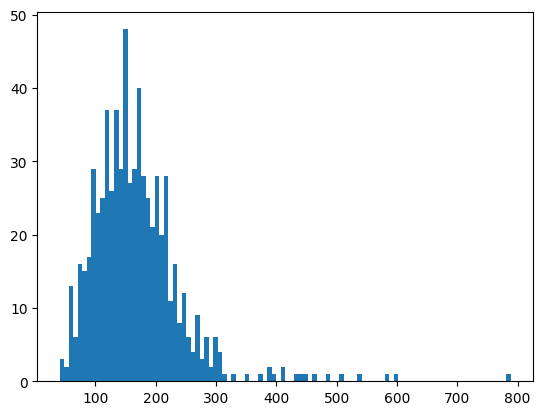

In [51]:
plt.hist([Descriptors.MolWt(Chem.MolFromSmiles(smiles)) for smiles in Cheon_lab_all_candidate_hist['Smiles']], bins=100)
plt.show()

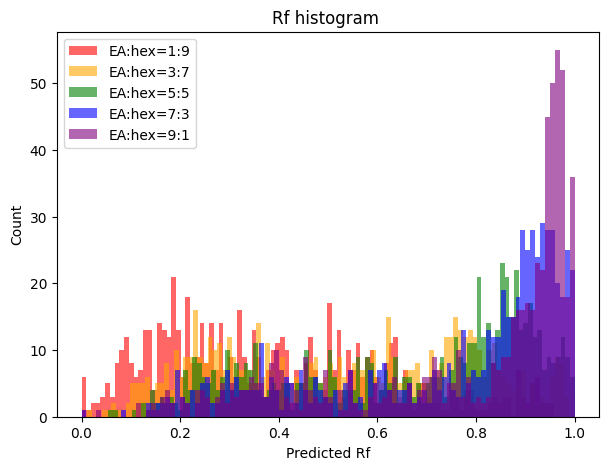

In [62]:
hists = [Cheon_lab_all_candidate_hist['EA/Hex (1:9)'],
Cheon_lab_all_candidate_hist['EA/Hex (3:7)'],
Cheon_lab_all_candidate_hist['EA/Hex (5:5)']]

fig = plt.figure(figsize=(7,5))
color=['red', 'orange', 'green']
data_label = ['1:9', '3:7', '5:5']
for i, data in enumerate(hists):
    plt.hist(
        data,
        alpha=0.6,
        bins = 100,
        color = color[i],
        density=False,
        label=f'EA:hex={data_label[i]}')

#-----

hists = [Cheon_lab_all_candidate_hist['EA/Hex (7:3)'],
Cheon_lab_all_candidate_hist['EA/Hex (9:1)']]

color=['blue', 'purple']
data_label = ['7:3', '9:1']
for i, data in enumerate(hists):
    plt.hist(
        data,
        alpha=0.6,
        bins = 100,
        color = color[i],
        density=False,
        label=f'EA:hex={data_label[i]}')

plt.title('Rf histogram ')
plt.xlabel('Predicted Rf')
plt.ylabel('Count')
plt.legend()
plt.show()

In [89]:
Cheon_lab_all_candidate

,카테고리 분류,카테고리 이름,관리번호,사내관리번호,물품명,서브네임,위치 경로,보관함 경로,브랜드,등록자,...,EA/Hex (1:9),EA/Hex (2:8),EA/Hex (3:7),EA/Hex (4:6),EA/Hex (5:5),EA/Hex (6:4),EA/Hex (7:3),EA/Hex (8:2),EA/Hex (9:1),EA/Hex (10:0)
0,화학물질,시약,D-1-1751,-,"2,5-dimethyl-1-phenyl-1h-pyrrole-3-carboxylic",-,D-1,D-1,Enamine,박상준,...,0.184187,0.244678,0.257396,0.250266,0.237514,0.250114,0.292245,0.346897,0.398232,0.421105
1,화학물질,시약,S-10-1740,-,"1,2-Bis(diphenylphosphino)benzene",97%,S-10,S-10,Sigma-Aldrich,박상준,...,0.334358,0.320235,0.295112,0.283809,0.299406,0.333707,0.349975,0.347715,0.336826,0.338902
2,화학물질,시약,D-5-1739,-,Triisopropyl phosphite,95%,D-1,D-1,Sigma-Aldrich,박상준,...,0.625073,0.647557,0.633539,0.604024,0.580708,0.550070,0.510640,0.474739,0.437916,0.394732
3,화학물질,시약,S-6s-1738,-,2-Fluorobenzonitrile,98%,S-6,S-6,Sigma-Aldrich,박상준,...,0.449331,0.644396,0.787646,0.863952,0.921609,0.942662,0.956822,0.967849,0.972150,0.972766
4,화학물질,시약,S-3L-1737,-,Morpholino(phenyl)methanone,-,"화학과 유기합성연구실의 물품 저장소,S-3L",S-3L,BLDpharm,박상준,...,0.183922,0.219896,0.272305,0.356106,0.379245,0.386810,0.396363,0.368501,0.341585,0.316073
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
739,화학물질,시약,R-B-1,-,Phosphorus oxychloride,-,R-B,R-B,DAEJUNG (대정),박진재,...,0.598815,0.675072,0.732652,0.770270,0.804763,0.857223,0.903894,0.931540,0.942610,0.954207
740,화학물질,시약,I-N-2,-,Thiophosphoryl chloride,-,I-N,I-N,TCI(Tokyo Chemical Industry),박진재,...,0.713231,0.780708,0.806311,0.837520,0.860436,0.893555,0.920635,0.934580,0.947980,0.959765
741,화학물질,시약,R-1-3,-,Phosphorus pentasulfide,-,R-1,R-1,Sigma-Aldrich,박진재,...,0.457814,0.461720,0.469805,0.464704,0.454080,0.458154,0.444308,0.414804,0.389365,0.350763
742,화학물질,시약,I-2-3,-,Boron-tribromide,-,I-2,I-2,Sigma-Aldrich,박진재,...,0.831406,0.864153,0.886898,0.917882,0.932452,0.943662,0.961350,0.986576,1.000000,1.000000


# 엑셀 파일에 분자 이미지 추가 및 저장

In [91]:
from rdkit.Chem import Draw
import os
import pandas as pd
from openpyxl import Workbook
from openpyxl.drawing.image import Image as XLImage

# SMILES 목록
smiles_list = Cheon_lab_all_candidate['Smiles']

# 분자 객체 리스트 생성
mols = [Chem.MolFromSmiles(smi) for smi in smiles_list]

# 각 분자의 PNG 이미지 파일로 저장하고, 파일명 리스트를 만듦
output_dir = 'molecule_images'
os.makedirs(output_dir, exist_ok=True)

image_file_names = []
for i, mol in enumerate(mols):
    img_filename = f"{output_dir}/mol_{i+1}.png"
    Draw.MolToFile(mol, img_filename, size=(200, 200))
    image_file_names.append(img_filename)

# 기존 DataFrame에 이미지 경로 칼럼 추가
df_excel = Cheon_lab_all_candidate.copy()
df_excel['이미지파일'] = image_file_names

# openpyxl로 DataFrame을 엑셀 파일에 저장하고, 각 셀에 이미지를 삽입
wb = Workbook()
ws = wb.active

# 데이터프레임 헤더 기록 (이미지 칼럼 포함)
for col_idx, col_name in enumerate(df_excel.columns, 1):
    ws.cell(row=1, column=col_idx, value=col_name)
# 행별 데이터 기록 (이미지 칼럼은 나중에 삽입)
for row_idx, row in enumerate(df_excel.itertuples(index=False), 2):
    for col_idx, value in enumerate(row, 1):
        # 이미지 파일명 컬럼이면 비워두기 (이미지 삽입 예정)
        if df_excel.columns[col_idx-1] == '이미지파일':
            continue
        ws.cell(row=row_idx, column=col_idx, value=value)

# 이미지 삽입 (이미지 파일은 "이미지파일" 칼럼에 존재)
img_col_idx = df_excel.columns.get_loc('이미지파일') + 1
ws.column_dimensions[ws.cell(row=1, column=img_col_idx).column_letter].width = 30  # 이미지 컬럼 넓이

for row_idx, img_path in enumerate(df_excel['이미지파일'], 2):
    img = XLImage(img_path)
    cell_ref = ws.cell(row=row_idx, column=img_col_idx).coordinate
    ws.row_dimensions[row_idx].height = 190  # 이미지가 보이게 행 높이 조정
    ws.add_image(img, cell_ref)

wb.save('Cheon_lab_all_candidate_with_imgs.xlsx')


In [6]:
path = 'ckpt_paper/ckpt_<C_paper_final>_<tvt>_GAT_BLI_dropout0.3'

moltovol_input = pd.read_csv('./DB/Rf/moltovol.csv')

required_columns_moltovol = ['Smiles', 'eluent1_smiles', 'eluent2_smiles', 'ratio1', 'ratio2']
missing_columns_moltovol = [
    column for column in required_columns_moltovol
    if column not in moltovol_input.columns
]
if missing_columns_moltovol:
    raise ValueError(f'입력 파일에 필요한 컬럼이 없습니다: {missing_columns_moltovol}')

moltovol_model_input = moltovol_input.rename(columns={
    'eluent1_smiles': 'elu1_smiles',
    'eluent2_smiles': 'elu2_smiles'
}).copy()
moltovol_model_input['sample_id'] = moltovol_model_input.index
moltovol_model_input.to_csv('./DB/Rf/moltovol_model_input.csv', index=False)

moltovol_predict = make_graph_predict(
    model=GAT_BLI(),
    ckpt=path,
    csv_name='moltovol_model_input.csv'
)
moltovol_predict = np.clip(moltovol_predict, 0, 1)

moltovol_result = moltovol_input.copy()
moltovol_result['BLI_GAT_predicted_Rf'] = moltovol_predict
moltovol_result.to_csv('./DB/Rf/moltovol_with_prediction.csv', index=False)
moltovol_result.head()


>>> graph 만드는 중...


/tmp/ipykernel_3186185/735206890.py:7: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  opt_ckpt = torch.load((ckpt + '/opt_checkpoint.pt'))
Processing...


  0%|          | 0/8 [00:00<?, ?it/s]

Done!
Processing...


  0%|          | 0/8 [00:00<?, ?it/s]

Done!
Processing...


  0%|          | 0/8 [00:00<?, ?it/s]

Done!


>>> compound랑 eluent graph 모으는 중...
>>> dataloader 만드는 중...
>>> 예측 시작!
>> 예측 완료


,Smiles,eluent1_smiles,eluent2_smiles,ratio1,ratio2,Rf,set,Rf_type,DataSource,doi,BLI_GAT_predicted_Rf
0,C1=CC=C(C=C1)N,CCCCCC,CCOC(C)=O,1.000000,0.000000,0.04,NaN,C,cheonlab,a,0.011619
1,C1=CC=C(C=C1)N,CCCCCC,CCOC(C)=O,0.952381,0.047619,0.49,NaN,C,cheonlab,a,0.027002
2,C1=CC=C(C=C1)N,CCCCCC,CCOC(C)=O,0.937500,0.062500,0.62,NaN,C,cheonlab,a,0.035386
3,C1=CC=C(C=C1)N,CCCCCC,CCOC(C)=O,0.909091,0.090909,0.19,NaN,C,cheonlab,a,0.053142
4,C1=CC=C(C=C1)N,CCCCCC,CCOC(C)=O,0.833333,0.166667,0.67,NaN,C,cheonlab,a,0.113849


In [7]:
moltovol_copy1_input = pd.read_csv('./DB/Rf/moltovol_copy1.csv')

required_columns_moltovol_copy1 = ['Smiles', 'eluent1_smiles', 'eluent2_smiles', 'ratio1', 'ratio2']
missing_columns_moltovol_copy1 = [
    column for column in required_columns_moltovol_copy1
    if column not in moltovol_copy1_input.columns
]
if missing_columns_moltovol_copy1:
    raise ValueError(f'입력 파일에 필요한 컬럼이 없습니다: {missing_columns_moltovol_copy1}')

moltovol_copy1_model_input = moltovol_copy1_input.rename(columns={
    'eluent1_smiles': 'elu1_smiles',
    'eluent2_smiles': 'elu2_smiles'
}).copy()
moltovol_copy1_model_input['sample_id'] = moltovol_copy1_model_input.index
moltovol_copy1_model_input.to_csv('./DB/Rf/moltovol_copy1_model_input.csv', index=False)

moltovol_copy1_predict = make_graph_predict(
    model=GAT_BLI(),
    ckpt=path,
    csv_name='moltovol_copy1_model_input.csv'
)
moltovol_copy1_predict = np.clip(moltovol_copy1_predict, 0, 1)

moltovol_copy1_result = moltovol_copy1_input.copy()
moltovol_copy1_result['BLI_GAT_predicted_Rf'] = moltovol_copy1_predict
moltovol_copy1_result.to_csv('./DB/Rf/moltovol_copy1_with_prediction.csv', index=False)
moltovol_copy1_result.head()


>>> graph 만드는 중...


/tmp/ipykernel_3186185/735206890.py:7: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  opt_ckpt = torch.load((ckpt + '/opt_checkpoint.pt'))
Processing...


  0%|          | 0/11 [00:00<?, ?it/s]

Done!
Processing...


  0%|          | 0/11 [00:00<?, ?it/s]

Done!
Processing...


  0%|          | 0/11 [00:00<?, ?it/s]

>>> compound랑 eluent graph 모으는 중...
>>> dataloader 만드는 중...
>>> 예측 시작!
>> 예측 완료


Done!


,Smiles,eluent1_smiles,eluent2_smiles,ratio1,ratio2,Rf,set,Rf_type,DataSource,doi,BLI_GAT_predicted_Rf
0,C1=CC=C(C=C1)N,CCCCCC,CCOC(C)=O,1.000000,0.000000,0.1000,NaN,C,cheonlab,a,0.011619
1,C1=CC=C(C=C1)N,CCCCCC,CCOC(C)=O,0.990099,0.009900,0.1001,NaN,C,cheonlab,a,0.011895
2,C1=CC=C(C=C1)N,CCCCCC,CCOC(C)=O,0.980392,0.019608,0.5010,NaN,C,cheonlab,a,0.014268
3,C1=CC=C(C=C1)N,CCCCCC,CCOC(C)=O,0.967742,0.032258,0.3010,NaN,C,cheonlab,a,0.019021
4,C1=CC=C(C=C1)N,CCCCCC,CCOC(C)=O,0.952381,0.047619,0.2010,NaN,C,cheonlab,a,0.027002
